# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rafa Rizki Aira Swala | 5054251017 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Set random seed agar hasil eksperimen dapat direproduksi
torch.manual_seed(42)
np.random.seed(42)

# Set style visualisasi
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
# Load dataset
df = pd.read_csv('Churn_Modelling.csv')

# Tampilkan beberapa baris pertama
print("5 Baris Pertama Dataset")
display(df.head())

print("\nJumlah Baris dan Kolom")
print(f"Jumlah baris : {df.shape[0]}")
print(f"Jumlah kolom : {df.shape[1]}")

print("\nTipe Data Tiap Kolom")
print(df.dtypes)

print("\nStatistik Deskriptif")
display(df.describe())

print("\nJumlah Missing Value per Kolom")
print(df.isnull().sum())

5 Baris Pertama Dataset


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Jumlah Baris dan Kolom
Jumlah baris : 10000
Jumlah kolom : 14

Tipe Data Tiap Kolom
RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Statistik Deskriptif


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Jumlah Missing Value per Kolom
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Distribusi Kelas Target
Exited
0    7963
1    2037
Name: count, dtype: int64

Proporsi Churn: 20.37%
Proporsi Tidak Churn: 79.63%


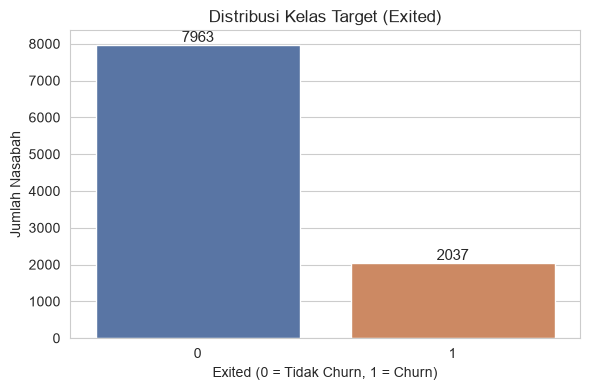


Interpretasi:
Dataset ini IMBALANCED karena jumlah kelas 'Tidak Churn' jauh lebih banyak
dibanding kelas 'Churn'. Ini penting untuk diperhatikan saat training,
salah satunya dengan menggunakan class weight.


In [24]:
# Tampilkan distribusi kelas target (Exited)
churn_counts = df['Exited'].value_counts()
print("Distribusi Kelas Target")
print(churn_counts)
print(f"\nProporsi Churn: {churn_counts[1] / len(df) * 100:.2f}%")
print(f"Proporsi Tidak Churn: {churn_counts[0] / len(df) * 100:.2f}%")

# Bar plot distribusi kelas
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Exited', data=df, hue='Exited',
                   palette=['#4C72B0', '#DD8452'], legend=False)
plt.title('Distribusi Kelas Target (Exited)')
plt.xlabel('Exited (0 = Tidak Churn, 1 = Churn)')
plt.ylabel('Jumlah Nasabah')

# Tambahkan label angka di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

# Interpretasi singkat
print("\nInterpretasi:")
print("Dataset ini IMBALANCED karena jumlah kelas 'Tidak Churn' jauh lebih banyak")
print("dibanding kelas 'Churn'. Ini penting untuk diperhatikan saat training,")
print("salah satunya dengan menggunakan class weight.")

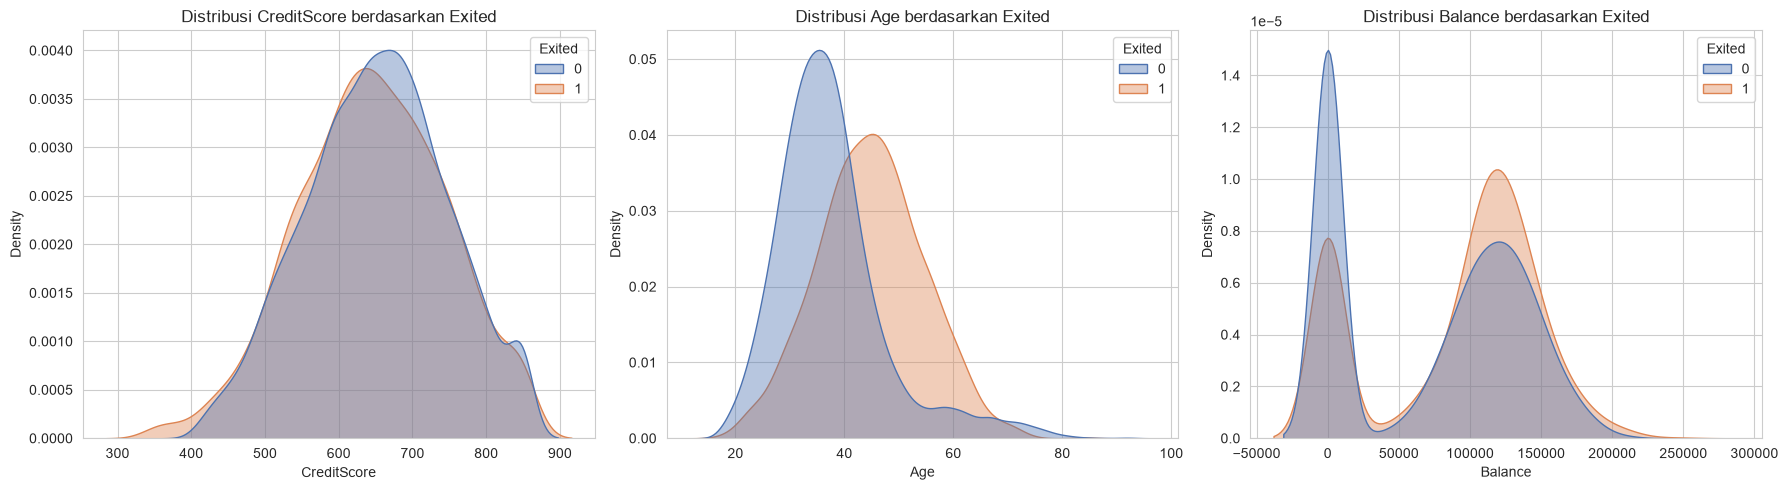

In [5]:
# Tampilkan distribusi fitur numerik (Age, CreditScore, Balance) berdasarkan kelas Exited
num_features = ['CreditScore', 'Age', 'Balance']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, num_features):
    sns.kdeplot(data=df, x=col, hue='Exited', common_norm=False,
                palette=['#4C72B0', '#DD8452'], fill=True, alpha=0.4, ax=ax)
    ax.set_title(f'Distribusi {col} berdasarkan Exited')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

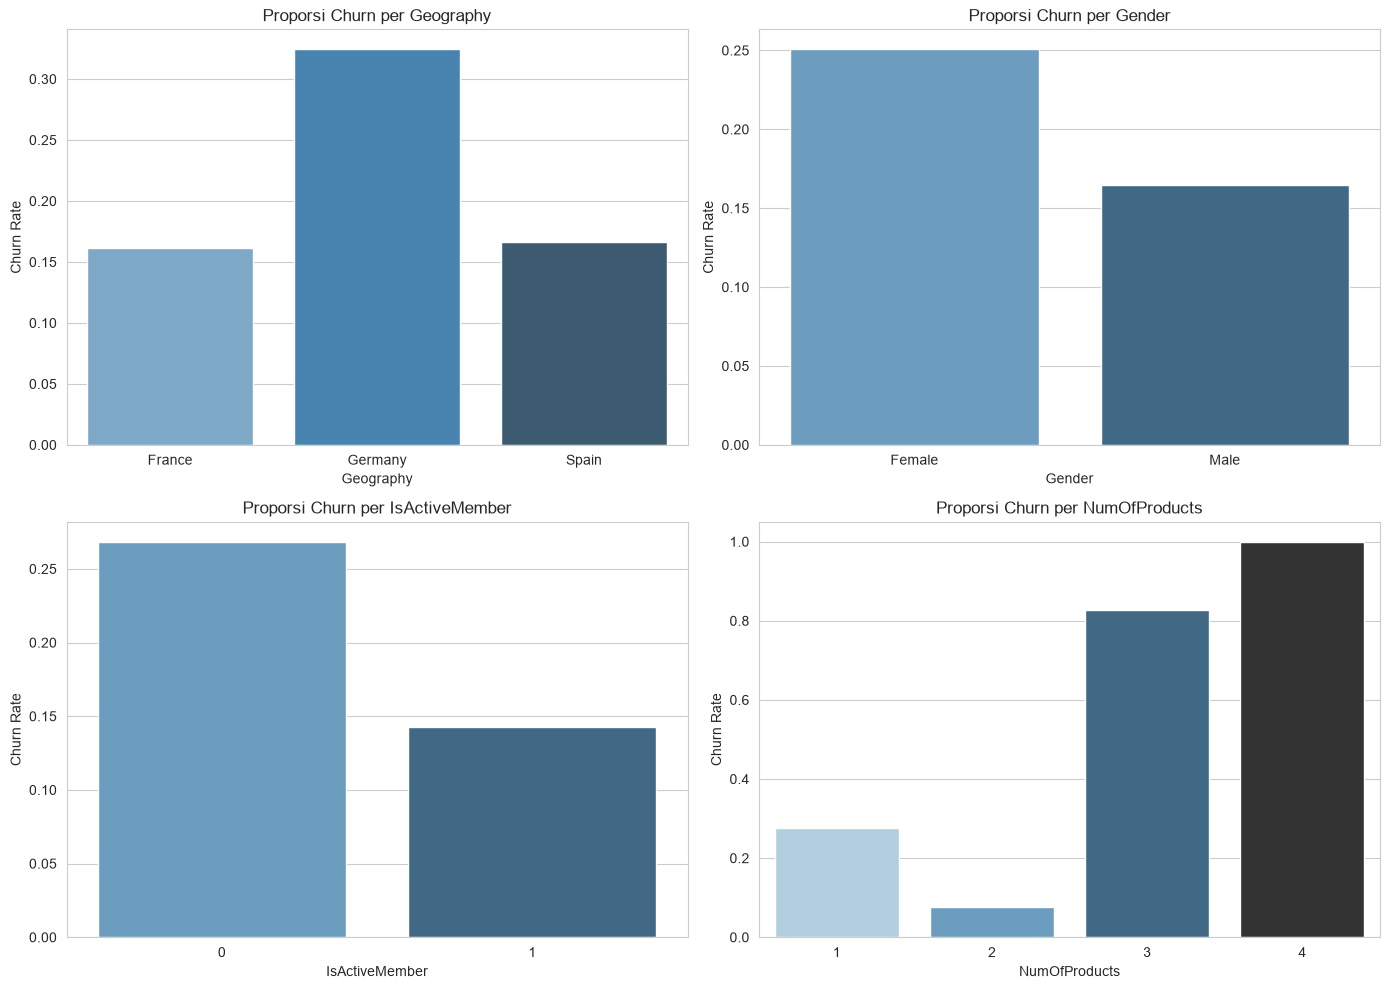

In [25]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal
cat_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, cat_features):
    # Hitung proporsi churn per kategori
    churn_prop = df.groupby(col)['Exited'].mean().reset_index()
    churn_prop.columns = [col, 'Churn Rate']

    sns.barplot(data=churn_prop, x=col, y='Churn Rate', hue=col,
                palette='Blues_d', legend=False, ax=ax)
    ax.set_title(f'Proporsi Churn per {col}')
    ax.set_ylabel('Churn Rate')

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [26]:
# Drop kolom yang tidak relevan untuk prediksi.
# Alasan:
# - RowNumber      : hanya nomor urut baris, tidak punya makna prediktif
# - CustomerId     : hanya identitas unik nasabah, tidak berkorelasi dengan churn
# - Surname        : nama nasabah, bersifat unik/kategorikal tinggi, tidak informatif
# Ketiga kolom ini jika dipakai justru berpotensi membuat model menghafal (leakage)
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

print("Kolom setelah drop:", df_clean.columns.tolist())
print("Shape:", df_clean.shape)
display(df_clean.head())

Kolom setelah drop: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Shape: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [27]:
# Pisahkan fitur (X) dan target (y)
X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']

# Split pertama: train (70%) vs temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split kedua: temp -> validation (15%) dan test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Ukuran data:")
print(f"Train      : {X_train.shape[0]} baris ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation : {X_val.shape[0]} baris ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test       : {X_test.shape[0]} baris ({X_test.shape[0]/len(X)*100:.1f}%)")

# Cek proporsi kelas di tiap set (stratify memastikan proporsinya mirip)
print("\nProporsi churn di tiap set:")
print(f"Train      : {y_train.mean()*100:.2f}%")
print(f"Validation : {y_val.mean()*100:.2f}%")
print(f"Test       : {y_test.mean()*100:.2f}%")

Ukuran data:
Train      : 7000 baris (70.0%)
Validation : 1500 baris (15.0%)
Test       : 1500 baris (15.0%)

Proporsi churn di tiap set:
Train      : 20.37%
Validation : 20.40%
Test       : 20.33%


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Tentukan kolom kategorikal dan numerik
cat_cols = ['Geography', 'Gender']
num_cols = [col for col in X_train.columns if col not in cat_cols]

print("Kolom kategorikal:", cat_cols)
print("Kolom numerik    :", num_cols)

# Buat ColumnTransformer
# - OneHotEncoder untuk kategorikal (handle_unknown='ignore' agar aman saat test)
# - StandardScaler untuk numerik
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

# Fit HANYA pada train set, lalu transform ke semua set
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep   = preprocessor.transform(X_val)
X_test_prep  = preprocessor.transform(X_test)

print("\nShape setelah preprocessing:")
print(f"X_train_prep : {X_train_prep.shape}")
print(f"X_val_prep   : {X_val_prep.shape}")
print(f"X_test_prep  : {X_test_prep.shape}")

Kolom kategorikal: ['Geography', 'Gender']
Kolom numerik    : ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Shape setelah preprocessing:
X_train_prep : (7000, 13)
X_val_prep   : (1500, 13)
X_test_prep  : (1500, 13)


In [29]:
# Ubah X dan y menjadi tensor float32
X_train_tensor = torch.tensor(X_train_prep, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_prep,   dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_prep,  dtype=torch.float32)

# y diubah ke shape (N, 1) agar sesuai output model
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_tensor   = torch.tensor(y_val.values,   dtype=torch.float32).view(-1, 1)
y_test_tensor  = torch.tensor(y_test.values,  dtype=torch.float32).view(-1, 1)

print("Shape tensor:")
print(f"X_train_tensor : {X_train_tensor.shape}")
print(f"y_train_tensor : {y_train_tensor.shape}")
print(f"X_val_tensor   : {X_val_tensor.shape}")
print(f"y_val_tensor   : {y_val_tensor.shape}")
print(f"X_test_tensor  : {X_test_tensor.shape}")
print(f"y_test_tensor  : {y_test_tensor.shape}")

# Buat DataLoader untuk train set (shuffle=True)
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# DataLoader untuk val dan test (shuffle=False, urutan tidak perlu diacak)
val_dataset  = TensorDataset(X_val_tensor, y_val_tensor)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"\nJumlah batch train : {len(train_loader)}")
print(f"Jumlah batch val   : {len(val_loader)}")
print(f"Jumlah batch test  : {len(test_loader)}")

Shape tensor:
X_train_tensor : torch.Size([7000, 13])
y_train_tensor : torch.Size([7000, 1])
X_val_tensor   : torch.Size([1500, 13])
y_val_tensor   : torch.Size([1500, 1])
X_test_tensor  : torch.Size([1500, 13])
y_test_tensor  : torch.Size([1500, 1])

Jumlah batch train : 110
Jumlah batch val   : 24
Jumlah batch test  : 24


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [31]:
from sklearn.linear_model import LogisticRegression

# Inisialisasi dan latih model Logistic Regression pada train set
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_prep, y_train)

# Prediksi pada test set
y_pred_logreg = logreg.predict(X_test_prep)
y_prob_logreg = logreg.predict_proba(X_test_prep)[:, 1]

print("Logistic Regression selesai dilatih.")
print(f"Jumlah prediksi test: {len(y_pred_logreg)}")
print(f"Contoh probabilitas kelas 1 (5 pertama): {y_prob_logreg[:5]}")

Logistic Regression selesai dilatih.
Jumlah prediksi test: 1500
Contoh probabilitas kelas 1 (5 pertama): [0.2361518  0.04820422 0.07336647 0.18564575 0.11441092]


In [33]:
# Fungsi training loop reusable untuk 3.2, 3.3, dan 3.4
def train_model(model, train_loader, val_loader, criterion, optimizer,
                epochs=50, device='cpu', verbose=True):
    model.to(device)

    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': []
    }

    for epoch in range(epochs):
        # Training phase
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total

        # Validation phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                logits = model(X_batch)
                loss = criterion(logits, y_batch)

                val_loss += loss.item() * X_batch.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_loss = val_loss / val_total
        val_acc  = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if verbose and (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1:3d}/{epochs}] "
                  f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                  f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    return history

In [34]:
# Fungsi plot learning curve reusable
def plot_learning_curve(history, title='Learning Curve'):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history['train_loss'], label='Train Loss', color='#4C72B0')
    axes[0].plot(history['val_loss'],   label='Val Loss',   color='#DD8452')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    # Accuracy
    axes[1].plot(history['train_acc'], label='Train Acc', color='#4C72B0')
    axes[1].plot(history['val_acc'],   label='Val Acc',   color='#DD8452')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [35]:
input_dim = X_train_tensor.shape[1]

class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # output logit, 1 unit karena binary
        )

    def forward(self, x):
        return self.net(x)

model_32 = SimpleANN(input_dim)
print(model_32)
print(f"\nJumlah parameter: {sum(p.numel() for p in model_32.parameters())}")

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=13, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)

Jumlah parameter: 241


Device: cpu
Epoch [  5/50] train_loss=0.4197 train_acc=0.8149 | val_loss=0.4023 val_acc=0.8200
Epoch [ 10/50] train_loss=0.3788 train_acc=0.8410 | val_loss=0.3638 val_acc=0.8433
Epoch [ 15/50] train_loss=0.3555 train_acc=0.8531 | val_loss=0.3426 val_acc=0.8567
Epoch [ 20/50] train_loss=0.3479 train_acc=0.8566 | val_loss=0.3337 val_acc=0.8620
Epoch [ 25/50] train_loss=0.3450 train_acc=0.8574 | val_loss=0.3299 val_acc=0.8620
Epoch [ 30/50] train_loss=0.3439 train_acc=0.8576 | val_loss=0.3284 val_acc=0.8620
Epoch [ 35/50] train_loss=0.3426 train_acc=0.8589 | val_loss=0.3278 val_acc=0.8607
Epoch [ 40/50] train_loss=0.3417 train_acc=0.8566 | val_loss=0.3264 val_acc=0.8607
Epoch [ 45/50] train_loss=0.3410 train_acc=0.8580 | val_loss=0.3267 val_acc=0.8673
Epoch [ 50/50] train_loss=0.3407 train_acc=0.8586 | val_loss=0.3244 val_acc=0.8640


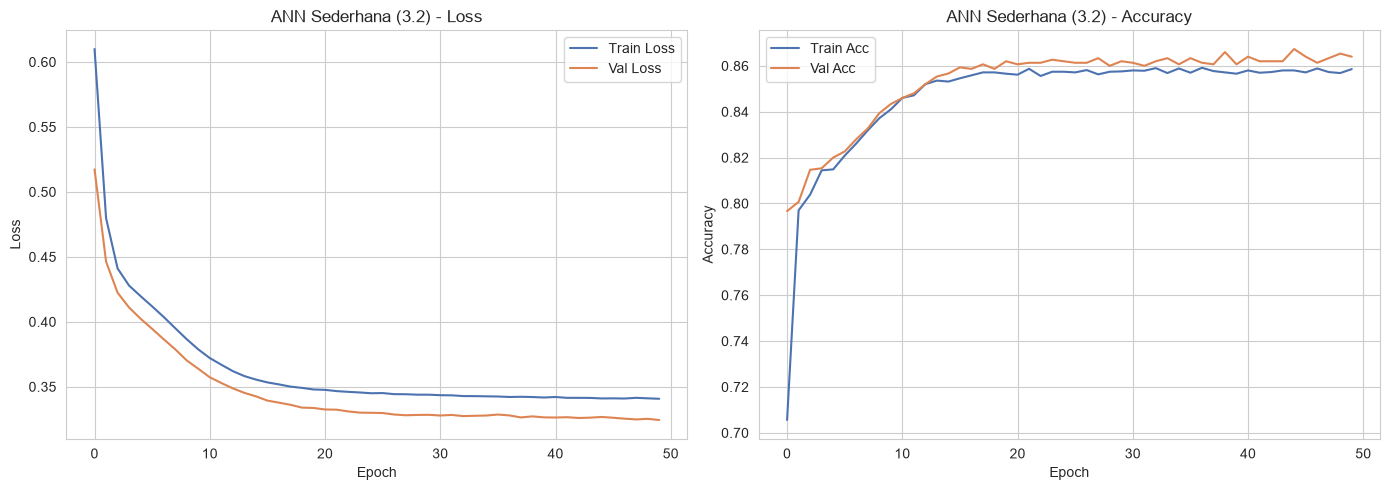

In [36]:
# Latih model 3.2
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_32.parameters(), lr=0.001)
EPOCHS = 50

history_32 = train_model(model_32, train_loader, val_loader,
                         criterion, optimizer, epochs=EPOCHS, device=device)

plot_learning_curve(history_32, title='ANN Sederhana (3.2)')

In [37]:
# Prediksi pada test set untuk model 3.2
model_32.eval()
with torch.no_grad():
    logits_32 = model_32(X_test_tensor.to(device)).cpu()
    prob_32 = torch.sigmoid(logits_32).numpy().flatten()
    pred_32 = (prob_32 >= 0.5).astype(int)

print("Prediksi test model 3.2 selesai.")
print(f"Contoh probabilitas (5 pertama): {prob_32[:5]}")
print(f"Contoh label (5 pertama): {pred_32[:5]}")

Prediksi test model 3.2 selesai.
Contoh probabilitas (5 pertama): [0.18655021 0.01670321 0.05696951 0.07929756 0.19595091]
Contoh label (5 pertama): [0 0 0 0 0]


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [38]:
# Dropout hanya aktif saat model.train() dan nonaktif saat model.eval()
class DeepANN(nn.Module):
    def __init__(self, input_dim, p_dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

model_33 = DeepANN(input_dim, p_dropout=0.3)
print(model_33)
print(f"\nJumlah parameter: {sum(p.numel() for p in model_33.parameters())}")

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=16, out_features=1, bias=True)
  )
)

Jumlah parameter: 3521


Epoch [  5/50] train_loss=0.4198 train_acc=0.8286 | val_loss=0.3610 val_acc=0.8513
Epoch [ 10/50] train_loss=0.3829 train_acc=0.8457 | val_loss=0.3394 val_acc=0.8613
Epoch [ 15/50] train_loss=0.3726 train_acc=0.8544 | val_loss=0.3327 val_acc=0.8593
Epoch [ 20/50] train_loss=0.3628 train_acc=0.8571 | val_loss=0.3242 val_acc=0.8667
Epoch [ 25/50] train_loss=0.3538 train_acc=0.8583 | val_loss=0.3267 val_acc=0.8680
Epoch [ 30/50] train_loss=0.3558 train_acc=0.8599 | val_loss=0.3272 val_acc=0.8647
Epoch [ 35/50] train_loss=0.3483 train_acc=0.8630 | val_loss=0.3237 val_acc=0.8667
Epoch [ 40/50] train_loss=0.3477 train_acc=0.8621 | val_loss=0.3202 val_acc=0.8693
Epoch [ 45/50] train_loss=0.3433 train_acc=0.8644 | val_loss=0.3233 val_acc=0.8680
Epoch [ 50/50] train_loss=0.3410 train_acc=0.8646 | val_loss=0.3209 val_acc=0.8633


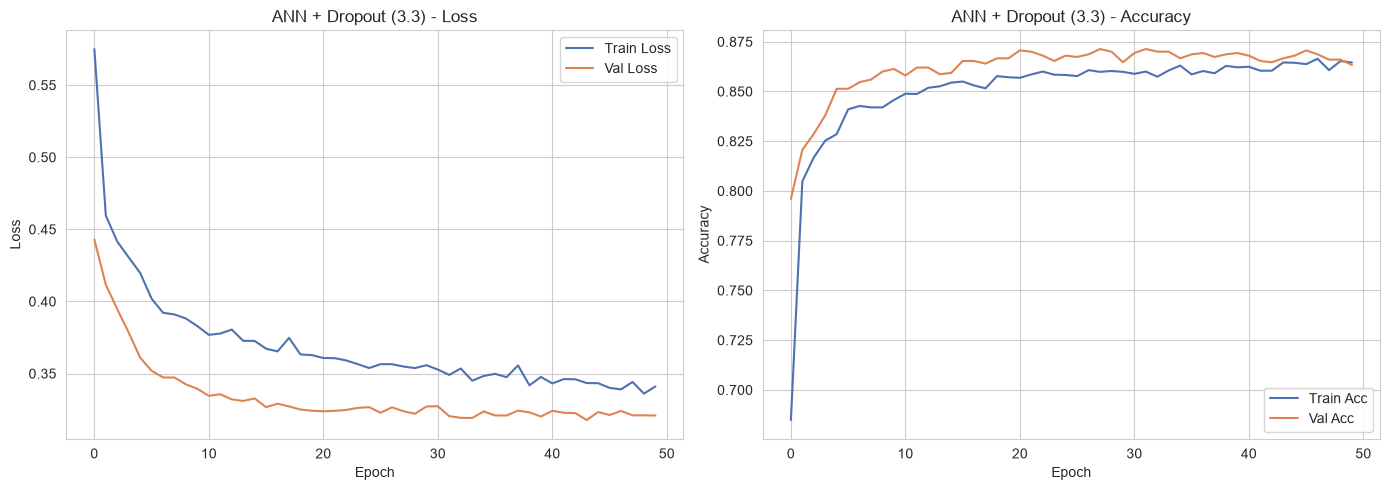


Perbandingan akhir training (epoch terakhir):
3.2 ANN Sederhana : train_loss=0.3407, val_loss=0.3244, gap=-0.0164
3.3 ANN + Dropout : train_loss=0.3410, val_loss=0.3209, gap=-0.0201

Gap yang besar (val_loss >> train_loss) mengindikasikan overfitting.


In [39]:
optimizer_33 = optim.Adam(model_33.parameters(), lr=0.001)

history_33 = train_model(model_33, train_loader, val_loader,
                         criterion, optimizer_33, epochs=EPOCHS, device=device)

plot_learning_curve(history_33, title='ANN + Dropout (3.3)')

# Bandingkan dengan 3.2
print("\nPerbandingan akhir training (epoch terakhir):")
print(f"3.2 ANN Sederhana : train_loss={history_32['train_loss'][-1]:.4f}, "
      f"val_loss={history_32['val_loss'][-1]:.4f}, "
      f"gap={history_32['val_loss'][-1] - history_32['train_loss'][-1]:.4f}")
print(f"3.3 ANN + Dropout : train_loss={history_33['train_loss'][-1]:.4f}, "
      f"val_loss={history_33['val_loss'][-1]:.4f}, "
      f"gap={history_33['val_loss'][-1] - history_33['train_loss'][-1]:.4f}")
print("\nGap yang besar (val_loss >> train_loss) mengindikasikan overfitting.")

In [40]:
# Prediksi pada test set untuk model 3.3
model_33.eval()
with torch.no_grad():
    logits_33 = model_33(X_test_tensor.to(device)).cpu()
    prob_33 = torch.sigmoid(logits_33).numpy().flatten()
    pred_33 = (prob_33 >= 0.5).astype(int)

print("Prediksi test model 3.3 selesai.")
print(f"Contoh probabilitas (5 pertama): {prob_33[:5]}")
print(f"Contoh label (5 pertama): {pred_33[:5]}")

Prediksi test model 3.3 selesai.
Contoh probabilitas (5 pertama): [0.1278866  0.01282234 0.04535567 0.06934238 0.20164308]
Contoh label (5 pertama): [0 0 0 0 0]


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [41]:
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight = n_neg / n_pos
print(f"Jumlah kelas 0 (train): {n_neg}")
print(f"Jumlah kelas 1 (train): {n_pos}")
print(f"pos_weight = {pos_weight:.4f}")

# Buat ulang model (arsitektur terbaik dari 3.2 atau 3.3)
# Di sini kita pakai arsitektur DeepANN (3.3) karena lebih representatif
model_34 = DeepANN(input_dim, p_dropout=0.3)

# Loss dengan pos_weight
criterion_34 = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer_34 = optim.Adam(model_34.parameters(), lr=0.001)

Jumlah kelas 0 (train): 5574
Jumlah kelas 1 (train): 1426
pos_weight = 3.9088


Epoch [  5/50] train_loss=0.8492 train_acc=0.7446 | val_loss=0.7710 val_acc=0.7560
Epoch [ 10/50] train_loss=0.8029 train_acc=0.7781 | val_loss=0.7308 val_acc=0.8067
Epoch [ 15/50] train_loss=0.7800 train_acc=0.7833 | val_loss=0.7069 val_acc=0.7960
Epoch [ 20/50] train_loss=0.7678 train_acc=0.7754 | val_loss=0.7054 val_acc=0.7800
Epoch [ 25/50] train_loss=0.7597 train_acc=0.7881 | val_loss=0.6951 val_acc=0.7973
Epoch [ 30/50] train_loss=0.7558 train_acc=0.7829 | val_loss=0.7165 val_acc=0.7727
Epoch [ 35/50] train_loss=0.7375 train_acc=0.7763 | val_loss=0.7067 val_acc=0.7793
Epoch [ 40/50] train_loss=0.7396 train_acc=0.7840 | val_loss=0.7010 val_acc=0.7860
Epoch [ 45/50] train_loss=0.7298 train_acc=0.7817 | val_loss=0.7060 val_acc=0.7633
Epoch [ 50/50] train_loss=0.7348 train_acc=0.7804 | val_loss=0.7100 val_acc=0.7727


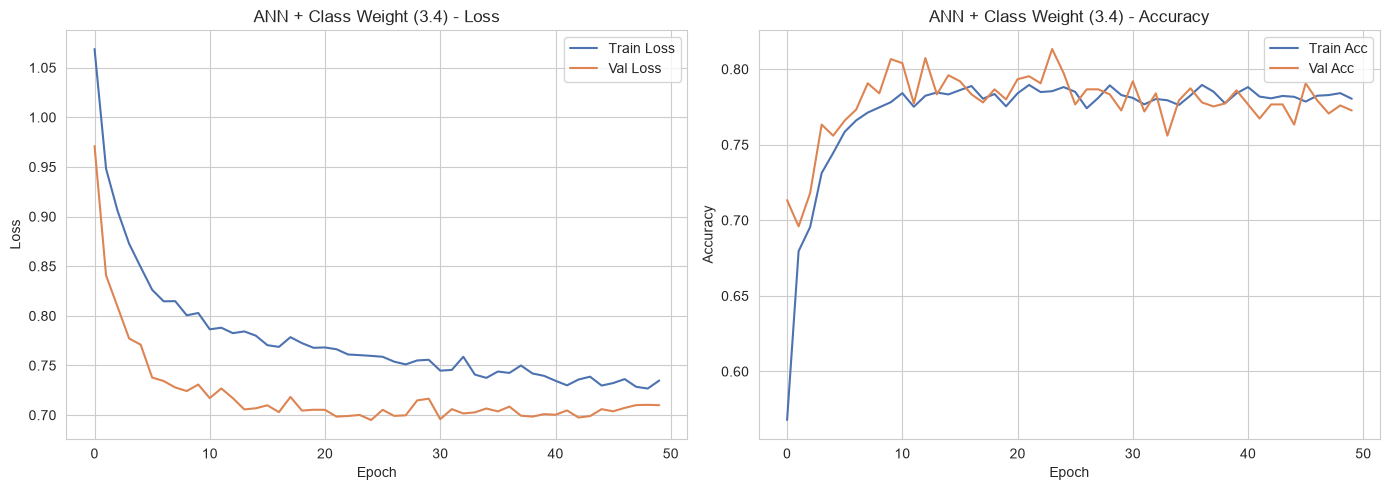

In [42]:
# Latih model 3.4 dengan class weight
history_34 = train_model(model_34, train_loader, val_loader,
                         criterion_34, optimizer_34, epochs=EPOCHS, device=device)

plot_learning_curve(history_34, title='ANN + Class Weight (3.4)')

In [43]:
# Prediksi pada test set untuk model 3.4
model_34.eval()
with torch.no_grad():
    logits_34 = model_34(X_test_tensor.to(device)).cpu()
    prob_34 = torch.sigmoid(logits_34).numpy().flatten()
    pred_34 = (prob_34 >= 0.5).astype(int)

print("Prediksi test model 3.4 selesai.")
print(f"Contoh probabilitas (5 pertama): {prob_34[:5]}")
print(f"Contoh label (5 pertama): {pred_34[:5]}")

Prediksi test model 3.4 selesai.
Contoh probabilitas (5 pertama): [0.42615235 0.13279942 0.15263677 0.31489536 0.5491127 ]
Contoh label (5 pertama): [0 0 0 0 1]


# 4. Evaluasi Model

In [44]:
# Tabel perbandingan metrik evaluasi semua model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def evaluate_model(y_true, y_pred, y_prob, model_name):
    return {
        'Model'    : model_name,
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall'   : recall_score(y_true, y_pred),
        'F1-Score' : f1_score(y_true, y_pred),
        'AUC'      : roc_auc_score(y_true, y_prob)
    }

y_test_np = y_test.values

results = [
    evaluate_model(y_test_np, y_pred_logreg, y_prob_logreg, '3.1 Logistic Regression'),
    evaluate_model(y_test_np, pred_32,      prob_32,      '3.2 ANN Sederhana'),
    evaluate_model(y_test_np, pred_33,      prob_33,      '3.3 ANN + Dropout'),
    evaluate_model(y_test_np, pred_34,      prob_34,      '3.4 ANN + Class Weight'),
]

df_results = pd.DataFrame(results).set_index('Model')
df_results_rounded = df_results.round(4)

print("Tabel Perbandingan Metrik Evaluasi")
display(df_results_rounded)

Tabel Perbandingan Metrik Evaluasi


,Accuracy,Precision,Recall,F1-Score,AUC
Model,,,,,
3.1 Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7912
3.2 ANN Sederhana,0.8680,0.7744,0.4951,0.6040,0.8661
3.3 ANN + Dropout,0.8640,0.8024,0.4393,0.5678,0.8629
3.4 ANN + Class Weight,0.7707,0.4630,0.8000,0.5865,0.8657


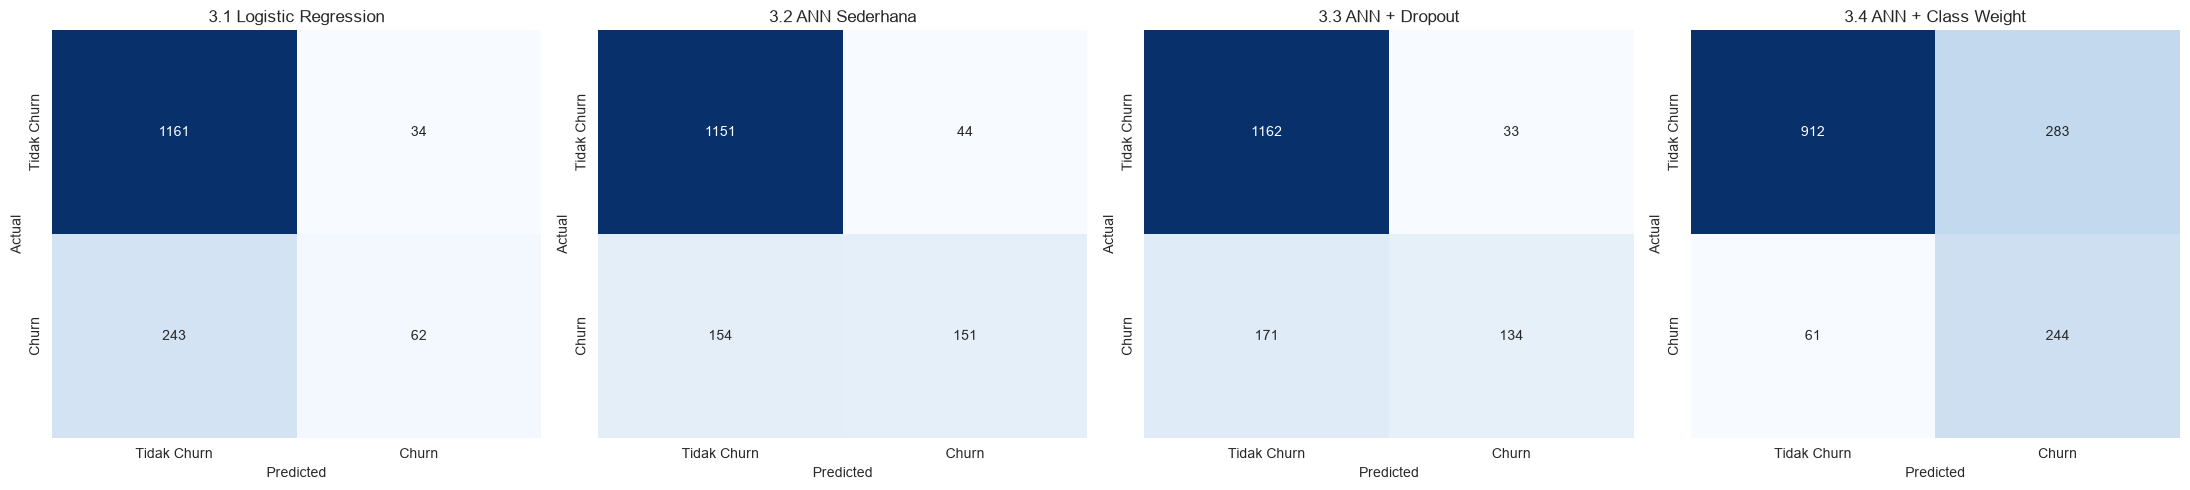

In [45]:
# Confusion Matrix setiap model dalam satu baris subplot
from sklearn.metrics import confusion_matrix

models_preds = [
    ('3.1 Logistic Regression', y_pred_logreg),
    ('3.2 ANN Sederhana',       pred_32),
    ('3.3 ANN + Dropout',       pred_33),
    ('3.4 ANN + Class Weight',  pred_34),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (name, preds) in zip(axes, models_preds):
    cm = confusion_matrix(y_test_np, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Tidak Churn', 'Churn'],
                yticklabels=['Tidak Churn', 'Churn'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
# ROC Curve seluruh model dalam satu plot beserta nilai AUC
from sklearn.metrics import roc_curve, roc_auc_score

models_probs = [
    ('3.1 Logistic Regression', y_prob_logreg),
    ('3.2 ANN Sederhana',       prob_32),
    ('3.3 ANN + Dropout',       prob_33),
    ('3.4 ANN + Class Weight',  prob_34),
]

plt.figure(figsize=(9, 7))

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for (name, probs), color in zip(models_probs, colors):
    fpr, tpr, _ = roc_curve(y_test_np, probs)
    auc = roc_auc_score(y_test_np, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', color=color, linewidth=2)

# Garis diagonal (random classifier)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random (AUC = 0.5)')

plt.title('ROC Curve Perbandingan Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Analisis

### 5.1 Perbandingan Model

| Model | Accuracy | Precision | Recall | F1-Score | AUC |
|---|---|---|---|---|---|
| 3.1 Logistic Regression | 0.8153 | 0.6458 | 0.2033 | 0.3092 | 0.7912 |
| 3.2 ANN Sederhana | **0.8680** | 0.7744 | 0.4951 | **0.6040** | **0.8661** |
| 3.3 ANN + Dropout | 0.8640 | **0.8024** | 0.4393 | 0.5678 | 0.8629 |
| 3.4 ANN + Class Weight | 0.7707 | 0.4630 | **0.8000** | 0.5865 | 0.8657 |

Semua konfigurasi ANN mengungguli Logistic Regression. Baseline linear hanya mendapat F1 0.3092 dan AUC 0.7912, sedangkan ANN terbaik mencapai F1 0.6040 dan AUC 0.8661. Ini menunjukkan hubungan antar fitur dengan churn bersifat non-linear, sehingga ANN lebih cocok dibanding model linear.

### 5.2 Logistic Regression vs ANN

Logistic Regression punya precision cukup tinggi (0.6458) tetapi recall sangat rendah (0.2033). Artinya model ini terlalu konservatif: dari 305 nasabah yang benar-benar churn, hanya 62 yang berhasil terdeteksi. Pola ini khas pada dataset imbalanced, di mana model linear cenderung menebak kelas mayoritas untuk meminimalkan loss keseluruhan.

ANN Sederhana (3.2) memperbaiki hampir semua aspek: recall naik dari 0.2033 ke 0.4951, F1 dari 0.3092 ke 0.6040, dan AUC dari 0.7912 ke 0.8661. Peningkatan ini membuktikan ANN mampu menangkap pola non-linear seperti interaksi antar fitur yang tidak tertangkap model linear.

### 5.3 Learning Curve dan Overfitting

Ketiga model ANN menunjukkan kurva yang sehat, tanpa indikasi overfitting. Gap antara train loss dan val loss sangat kecil, bahkan negatif. Ini wajar karena val loss diukur setelah model di-update penuh di akhir epoch, dan ukuran val set lebih kecil (1.500 vs 7.000) sehingga variansinya lebih besar.

- **3.2 ANN Sederhana**: gap loss −0.0164, gap accuracy −0.0054, diagnosis FIT.
- **3.3 ANN + Dropout**: gap loss −0.0201, gap accuracy +0.0012, diagnosis FIT. Dropout berhasil mencegah overfitting meskipun model lebih dalam.
- **3.4 ANN + Class Weight**: accuracy train dan val sama-sama rendah (~0.78) karena model sengaja dibuat lebih agresif menebak churn. Ini bukan underfitting, melainkan trade-off dari class weight.

Dengan 50 epoch dan arsitektur yang masih moderat, model belum cukup waktu untuk mulai menghafal data training.

### 5.4 Pengaruh Layer Tambahan dan Dropout (3.2 → 3.3)

| Metrik | 3.2 | 3.3 | Delta |
|---|---|---|---|
| Accuracy | 0.8680 | 0.8640 | −0.0040 |
| Precision | 0.7744 | **0.8024** | +0.0280 |
| Recall | **0.4951** | 0.4393 | −0.0558 |
| F1-Score | **0.6040** | 0.5678 | −0.0362 |
| AUC | **0.8661** | 0.8629 | −0.0032 |

Penambahan layer dan Dropout membuat model lebih berhati-hati: precision naik 2.8 poin, tetapi recall turun 5.6 poin. False Positive berkurang (44 → 33), namun False Negative bertambah (154 → 171). Secara keseluruhan F1 turun sedikit, jadi untuk dataset sekecil ini arsitektur dangkal (3.2) lebih efisien. Dropout tetap bermanfaat mencegah overfitting, tetapi belum cukup untuk mengungguli model sederhana tanpa tuning lebih lanjut.

### 5.5 Pengaruh Class Weight (3.3 → 3.4)

| Metrik | 3.3 | 3.4 | Delta |
|---|---|---|---|
| Precision | 0.8024 | 0.4630 | −0.3394 |
| Recall | 0.4393 | 0.8000 | +0.3607 |
| F1-Score | 0.5678 | 0.5865 | +0.0187 |
| AUC | 0.8629 | 0.8657 | +0.0028 |
| Accuracy | 0.8640 | 0.7707 | −0.0933 |

Class weight memberikan efek paling dramatis. Dengan `pos_weight ≈ 4.08`, model mengorbankan precision untuk mengejar recall. Recall melonjak dari 0.4393 ke 0.8000, sehingga 80% nasabah churn berhasil terdeteksi. False Negative turun drastis dari 171 ke 61. Namun precision jatuh ke 0.4630 karena banyak nasabah tidak churn ikut ditebak churn (False Positive naik dari 33 ke 283).

Meskipun precision turun banyak, F1-Score dan AUC justru sedikit naik. Ini menandakan trade-off-nya menguntungkan secara keseluruhan. Dalam konteks churn prediction, False Negative biasanya lebih mahal daripada False Positive, sehingga model 3.4 relevan jika prioritasnya menangkap sebanyak mungkin nasabah berisiko.

### 5.6 Model Terbaik

Tidak ada satu model yang menang di semua metrik, dan ini konsekuensi langsung dari dataset imbalanced.

- **Terbaik secara Accuracy, F1-Score, dan AUC**: model 3.2 ANN Sederhana (0.8680 / 0.6040 / 0.8661). Konfigurasi paling sederhana justru paling seimbang untuk dataset ini.
- **Terbaik secara Precision**: model 3.3 ANN + Dropout (0.8024). Cocok jika False Positive mahal.
- **Terbaik secara Recall**: model 3.4 ANN + Class Weight (0.8000). Cocok jika False Negative mahal.

Pemilihan model final sebaiknya mempertimbangkan biaya bisnis dari masing-masing jenis error, bukan sekadar mengejar accuracy tertinggi.

# 6. Kesimpulan dan Saran

### 6.1 Kesimpulan

1. **ANN mengungguli Logistic Regression secara signifikan.** Baseline linear hanya mencapai F1 0.3092 dan AUC 0.7912, sedangkan ANN terbaik (3.2) mencapai F1 0.6040 dan AUC 0.8661. Ini membuktikan hubungan antar fitur dengan churn bersifat non-linear, sehingga ANN lebih tepat digunakan pada dataset ini.

2. **Tidak terjadi overfitting berarti pada semua konfigurasi ANN.** Gap train dan validation loss sangat kecil, bahkan negatif karena cara pengukuran val loss dan ukuran val set yang lebih kecil. Dengan 50 epoch dan arsitektur moderat, model belum cukup waktu untuk menghafal data training.

3. **Penambahan layer dan Dropout (3.2 → 3.3) tidak selalu meningkatkan performa.** Precision naik 2.8 poin, tetapi recall dan F1 turun. Untuk dataset sekecil ini, arsitektur dangkal lebih efisien. Dropout tetap berguna mencegah overfitting, tetapi belum cukup untuk mengungguli model sederhana tanpa tuning lebih lanjut.

4. **Class weight (3.4) memberikan trade-off paling dramatis.** Recall melonjak dari 0.4393 ke 0.8000, dengan konsekuensi precision turun dari 0.8024 ke 0.4630. F1 dan AUC justru sedikit naik, menandakan trade-off ini menguntungkan secara keseluruhan. Model ini paling relevan jika tujuan utamanya menangkap sebanyak mungkin nasabah churn.

5. **Model 3.2 ANN Sederhana adalah pilihan paling seimbang** untuk dataset ini jika diukur dengan Accuracy, F1, dan AUC. Namun pemilihan model final sebaiknya mempertimbangkan konteks bisnis: gunakan 3.4 jika False Negative lebih mahal, atau 3.2/3.3 jika tim retensi punya kapasitas terbatas dan hanya ingin menyasar nasabah berisiko tinggi.

### 6.2 Saran

1. **Lakukan hyperparameter tuning.** Learning rate, jumlah neuron, jumlah layer, `p_dropout`, dan batch size masih menggunakan nilai default. Grid search atau Optuna bisa membantu menemukan konfigurasi yang lebih optimal.

2. **Tambahkan early stopping.** Saat ini training berjalan tetap 50 epoch. Dengan early stopping berdasarkan val loss, training bisa berhenti di titik terbaik dan menghemat waktu, sekaligus menghindari potensi overfitting pada epoch yang lebih panjang.

3. **Optimasi threshold klasifikasi.** Threshold default 0.5 belum tentu optimal untuk dataset imbalanced. Mencari threshold yang memaksimalkan F1 atau menyesuaikan dengan biaya bisnis bisa memberi hasil lebih baik.

4. **Eksplorasi teknik penanganan imbalanced lain.** Selain class weight, bisa dicoba SMOTE, undersampling, atau focal loss untuk melihat apakah hasilnya lebih baik dari model 3.4.

5. **Feature engineering.** Interaksi antar fitur seperti `Age × IsActiveMember` atau `Balance / Salary` berpotensi menambah informasi yang belum tertangkap model saat ini.

6. **Gunakan validasi silang (k-fold cross validation).** Hasil evaluasi saat ini bergantung pada satu kali split. Cross validation akan memberi estimasi performa yang lebih stabil dan mengurangi risiko hasil yang kebetulan bagus pada split tertentu.

7. **Simpan model terbaik untuk deployment.** Model 3.2 (atau model yang dipilih berdasarkan konteks bisnis) sebaiknya disimpan dalam bentuk `state_dict` beserta objek `preprocessor` (scaler dan encoder) agar konsisten saat inference nanti.